Imports (Efficient-KAN is embedded below, so no extra installation is needed)

In [1]:
import os
import math
import time
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

Load and clean the dataset

In [2]:
# same local path as the original notebook, with fallbacks for Colab / the current folder
_candidates = ["C:/Users/Benyamin/Documents/KAN/FinalDataNN.xlsx", "/content/FinalDataNN.xlsx", "FinalDataNN.xlsx"]
excel_path = next((p for p in _candidates if os.path.exists(p)), _candidates[0])
df = pd.read_excel(excel_path)

df_cleaned = df.dropna(subset=["P", "Y", "Ptest", "Ytest"])

P_train = df_cleaned["P"].values.astype("float32")
Y_train = df_cleaned["Y"].values.astype("float32")
P_test = df_cleaned["Ptest"].values.astype("float32")
Y_test = df_cleaned["Ytest"].values.astype("float32")

print(f"Train set size: {len(P_train)} samples")
print(f"Test set size: {len(P_test)} samples")

Train set size: 1072 samples
Test set size: 1072 samples


Hyper-parameters

In [3]:
# ---- Efficient-KAN hyper-parameters (defaults = Blealtan/efficient-kan KAN / KANLinear) ----
Grid_Size       = 5                # number of grid intervals
Spline_Order    = 3                # B-spline order
Scale_Noise     = 0.1
Scale_Base      = 1.0
Scale_Spline    = 1.0
Grid_Eps        = 0.02
Base_Activation = torch.nn.SiLU    # a class, exactly as in the repo
Cell_Grid_Range = [-1, 1]          # repo default; the recurrent cell only sees tanh-bounded inputs in [-1, 1]
Embed_Margin    = 0.1              # the embedding grid covers [min(P)-margin, max(P)+margin] of the training data
Embed_Grid_Range = [float(P_train.min()) - Embed_Margin, float(P_train.max()) + Embed_Margin]

# ---- recurrent-wrapper options (not part of the repo) ----
Use_Tanh_Bound  = True   # h_t = tanh(KAN([e_t ; h_{t-1}])) and e_t = tanh(KAN(chunk)); keeps every KAN input inside its grid
Reg_Weight      = 0.0    # weight of KAN.regularization_loss (0 = off, same loss as the original notebook)
Reg_Activation  = 1.0
Reg_Entropy     = 1.0

# ---- training / data hyper-parameters (same as the original notebook) ----
Batch_Size  = 32
Context_Len = 120
Pred_Len    = 20
H_Dims      = 32
N_Epochs    = 1500
Learning_Rate = 3e-4
Weight_Decay  = 0.01     # AdamW default, made explicit
Seq_Step = 5

print("Embedding grid range:", Embed_Grid_Range)

Embedding grid range: [-0.09913075601216406, 1.1]


Displaying Time Series

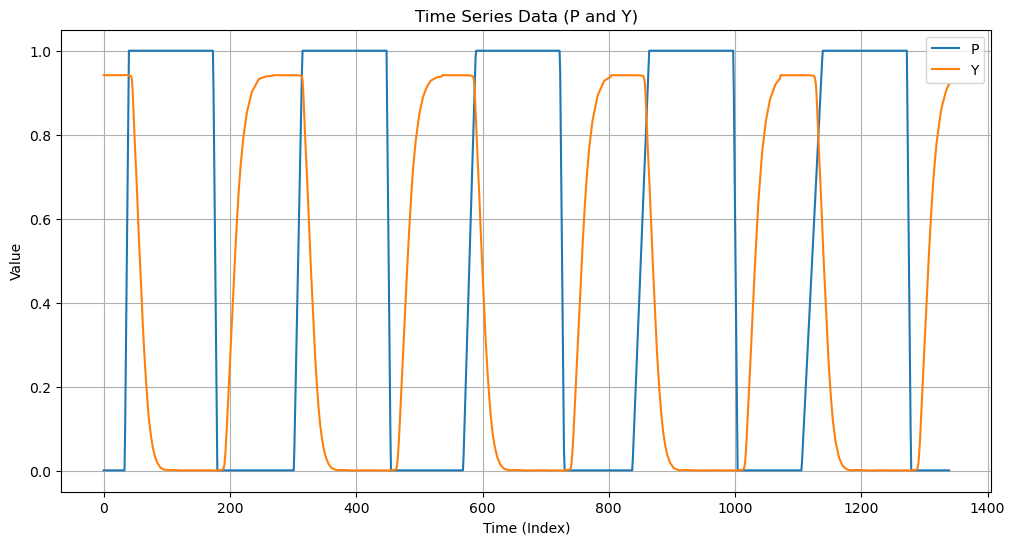

In [4]:
time_series_data_P = df["P"]
time_series_data_Y = df["Y"]

plt.figure(figsize=(12, 6))
plt.plot(time_series_data_P, label="P")
plt.plot(time_series_data_Y, label="Y")
plt.title("Time Series Data (P and Y)")
plt.xlabel("Time (Index)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

Sliding-window dataset (P → Y)

In [5]:
class PairedTimeSeriesDataset(Dataset):
    def __init__(self, x_series, y_series, context_len=Context_Len, pred_len=Pred_Len):
        self.x = torch.tensor(x_series, dtype=torch.float32)
        self.y = torch.tensor(y_series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len
        self.total_len = context_len + pred_len
        self.n_samples = max(len(self.x) - self.total_len + 1, 0)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_win = self.x[idx: idx + self.context_len]
        y_win = self.y[idx + self.context_len: idx + self.total_len]
        return x_win, y_win

train_dataset = PairedTimeSeriesDataset(P_train, Y_train)
test_dataset = PairedTimeSeriesDataset(P_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=Batch_Size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Batch_Size, shuffle=False)

print(f"Train windows: {len(train_dataset)}")
print(f"Test windows: {len(test_dataset)}")

Train windows: 933
Test windows: 933


Efficient-KAN layer (verbatim from Blealtan/efficient-kan, `src/efficient_kan/kan.py`, MIT licence)

In [6]:
class KANLinear(torch.nn.Module):
    def __init__(
        self,
        in_features,
        out_features,
        grid_size=5,
        spline_order=3,
        scale_noise=0.1,
        scale_base=1.0,
        scale_spline=1.0,
        enable_standalone_scale_spline=True,
        base_activation=torch.nn.SiLU,
        grid_eps=0.02,
        grid_range=[-1, 1],
    ):
        super(KANLinear, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.grid_size = grid_size
        self.spline_order = spline_order

        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = (
            (
                torch.arange(-spline_order, grid_size + spline_order + 1) * h
                + grid_range[0]
            )
            .expand(in_features, -1)
            .contiguous()
        )
        self.register_buffer("grid", grid)

        self.base_weight = torch.nn.Parameter(torch.Tensor(out_features, in_features))
        self.spline_weight = torch.nn.Parameter(
            torch.Tensor(out_features, in_features, grid_size + spline_order)
        )
        if enable_standalone_scale_spline:
            self.spline_scaler = torch.nn.Parameter(
                torch.Tensor(out_features, in_features)
            )

        self.scale_noise = scale_noise
        self.scale_base = scale_base
        self.scale_spline = scale_spline
        self.enable_standalone_scale_spline = enable_standalone_scale_spline
        self.base_activation = base_activation()
        self.grid_eps = grid_eps

        self.reset_parameters()

    def reset_parameters(self):
        torch.nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5) * self.scale_base)
        with torch.no_grad():
            noise = (
                (
                    torch.rand(self.grid_size + 1, self.in_features, self.out_features)
                    - 1 / 2
                )
                * self.scale_noise
                / self.grid_size
            )
            self.spline_weight.data.copy_(
                (self.scale_spline if not self.enable_standalone_scale_spline else 1.0)
                * self.curve2coeff(
                    self.grid.T[self.spline_order : -self.spline_order],
                    noise,
                )
            )
            if self.enable_standalone_scale_spline:
                # torch.nn.init.constant_(self.spline_scaler, self.scale_spline)
                torch.nn.init.kaiming_uniform_(self.spline_scaler, a=math.sqrt(5) * self.scale_spline)

    def b_splines(self, x: torch.Tensor):
        """
        Compute the B-spline bases for the given input tensor.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).

        Returns:
            torch.Tensor: B-spline bases tensor of shape (batch_size, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features

        grid: torch.Tensor = (
            self.grid
        )  # (in_features, grid_size + 2 * spline_order + 1)
        x = x.unsqueeze(-1)
        bases = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).to(x.dtype)
        for k in range(1, self.spline_order + 1):
            bases = (
                (x - grid[:, : -(k + 1)])
                / (grid[:, k:-1] - grid[:, : -(k + 1)])
                * bases[:, :, :-1]
            ) + (
                (grid[:, k + 1 :] - x)
                / (grid[:, k + 1 :] - grid[:, 1:(-k)])
                * bases[:, :, 1:]
            )

        assert bases.size() == (
            x.size(0),
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return bases.contiguous()

    def curve2coeff(self, x: torch.Tensor, y: torch.Tensor):
        """
        Compute the coefficients of the curve that interpolates the given points.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).
            y (torch.Tensor): Output tensor of shape (batch_size, in_features, out_features).

        Returns:
            torch.Tensor: Coefficients tensor of shape (out_features, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features
        assert y.size() == (x.size(0), self.in_features, self.out_features)

        A = self.b_splines(x).transpose(
            0, 1
        )  # (in_features, batch_size, grid_size + spline_order)
        B = y.transpose(0, 1)  # (in_features, batch_size, out_features)
        solution = torch.linalg.lstsq(
            A, B
        ).solution  # (in_features, grid_size + spline_order, out_features)
        result = solution.permute(
            2, 0, 1
        )  # (out_features, in_features, grid_size + spline_order)

        assert result.size() == (
            self.out_features,
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return result.contiguous()

    @property
    def scaled_spline_weight(self):
        return self.spline_weight * (
            self.spline_scaler.unsqueeze(-1)
            if self.enable_standalone_scale_spline
            else 1.0
        )

    def forward(self, x: torch.Tensor):
        assert x.size(-1) == self.in_features
        original_shape = x.shape
        x = x.reshape(-1, self.in_features)

        base_output = F.linear(self.base_activation(x), self.base_weight)
        spline_output = F.linear(
            self.b_splines(x).view(x.size(0), -1),
            self.scaled_spline_weight.view(self.out_features, -1),
        )
        output = base_output + spline_output
        
        output = output.reshape(*original_shape[:-1], self.out_features)
        return output

    @torch.no_grad()
    def update_grid(self, x: torch.Tensor, margin=0.01):
        assert x.dim() == 2 and x.size(1) == self.in_features
        batch = x.size(0)

        splines = self.b_splines(x)  # (batch, in, coeff)
        splines = splines.permute(1, 0, 2)  # (in, batch, coeff)
        orig_coeff = self.scaled_spline_weight  # (out, in, coeff)
        orig_coeff = orig_coeff.permute(1, 2, 0)  # (in, coeff, out)
        unreduced_spline_output = torch.bmm(splines, orig_coeff)  # (in, batch, out)
        unreduced_spline_output = unreduced_spline_output.permute(
            1, 0, 2
        )  # (batch, in, out)

        # sort each channel individually to collect data distribution
        x_sorted = torch.sort(x, dim=0)[0]
        grid_adaptive = x_sorted[
            torch.linspace(
                0, batch - 1, self.grid_size + 1, dtype=torch.int64, device=x.device
            )
        ]

        uniform_step = (x_sorted[-1] - x_sorted[0] + 2 * margin) / self.grid_size
        grid_uniform = (
            torch.arange(
                self.grid_size + 1, dtype=torch.float32, device=x.device
            ).unsqueeze(1)
            * uniform_step
            + x_sorted[0]
            - margin
        )

        grid = self.grid_eps * grid_uniform + (1 - self.grid_eps) * grid_adaptive
        grid = torch.concatenate(
            [
                grid[:1]
                - uniform_step
                * torch.arange(self.spline_order, 0, -1, device=x.device).unsqueeze(1),
                grid,
                grid[-1:]
                + uniform_step
                * torch.arange(1, self.spline_order + 1, device=x.device).unsqueeze(1),
            ],
            dim=0,
        )

        self.grid.copy_(grid.T)
        self.spline_weight.data.copy_(self.curve2coeff(x, unreduced_spline_output))

    def regularization_loss(self, regularize_activation=1.0, regularize_entropy=1.0):
        """
        Compute the regularization loss.

        This is a dumb simulation of the original L1 regularization as stated in the
        paper, since the original one requires computing absolutes and entropy from the
        expanded (batch, in_features, out_features) intermediate tensor, which is hidden
        behind the F.linear function if we want an memory efficient implementation.

        The L1 regularization is now computed as mean absolute value of the spline
        weights. The authors implementation also includes this term in addition to the
        sample-based regularization.
        """
        l1_fake = self.spline_weight.abs().mean(-1)
        regularization_loss_activation = l1_fake.sum()
        p = l1_fake / regularization_loss_activation
        regularization_loss_entropy = -torch.sum(p * p.log())
        return (
            regularize_activation * regularization_loss_activation
            + regularize_entropy * regularization_loss_entropy
        )


class KAN(torch.nn.Module):
    def __init__(
        self,
        layers_hidden,
        grid_size=5,
        spline_order=3,
        scale_noise=0.1,
        scale_base=1.0,
        scale_spline=1.0,
        base_activation=torch.nn.SiLU,
        grid_eps=0.02,
        grid_range=[-1, 1],
    ):
        super(KAN, self).__init__()
        self.grid_size = grid_size
        self.spline_order = spline_order

        self.layers = torch.nn.ModuleList()
        for in_features, out_features in zip(layers_hidden, layers_hidden[1:]):
            self.layers.append(
                KANLinear(
                    in_features,
                    out_features,
                    grid_size=grid_size,
                    spline_order=spline_order,
                    scale_noise=scale_noise,
                    scale_base=scale_base,
                    scale_spline=scale_spline,
                    base_activation=base_activation,
                    grid_eps=grid_eps,
                    grid_range=grid_range,
                )
            )

    def forward(self, x: torch.Tensor, update_grid=False):
        for layer in self.layers:
            if update_grid:
                layer.update_grid(x)
            x = layer(x)
        return x

    def regularization_loss(self, regularize_activation=1.0, regularize_entropy=1.0):
        return sum(
            layer.regularization_loss(regularize_activation, regularize_entropy)
            for layer in self.layers
        )


Efficient-KAN recurrent blocks

In [7]:
def make_kan(layers, grid_range):
    """Efficient-KAN network configured from the hyper-parameter cell."""
    return KAN(
        layers,
        grid_size=Grid_Size,
        spline_order=Spline_Order,
        scale_noise=Scale_Noise,
        scale_base=Scale_Base,
        scale_spline=Scale_Spline,
        base_activation=Base_Activation,
        grid_eps=Grid_Eps,
        grid_range=grid_range,
    )


class EfficientKANRNNCell(nn.Module):
    """
    A genuinely recurrent KAN cell: the hidden-state update
        h_t = tanh( KAN([x_t ; h_{t-1}]) )
    is computed by an Efficient-KAN network instead of the Linear + activation used by
    a vanilla RNN cell. The tanh keeps h_t inside the KAN grid range [-1, 1]
    (outside the grid the B-spline bases are zero and only the base branch remains).
    """
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.kan = make_kan([input_size + hidden_size, hidden_size], Cell_Grid_Range)

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        h_t = self.kan(combined)
        return torch.tanh(h_t) if Use_Tanh_Bound else h_t


class EfficientKANRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = EfficientKANRNNCell(input_size, hidden_size)
        self.readout = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        batch_size, seq_len, _ = x.shape
        if h0 is None:
            h_t = torch.zeros(batch_size, self.hidden_size, device=x.device, dtype=x.dtype)
        else:
            h_t = h0

        outputs = []
        for t in range(seq_len):
            h_t = self.cell(x[:, t, :], h_t)   # <-- recurrence: h_t depends on h_{t-1}
            outputs.append(self.readout(h_t).unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        return outputs, h_t


def kan_regularization(model):
    """Sum of the repo's KANLinear.regularization_loss over all KAN layers of the model."""
    return sum(m.regularization_loss(Reg_Activation, Reg_Entropy)
               for m in model.modules() if isinstance(m, KANLinear))


Main model: Recurrent Efficient KAN

In [8]:
class RecurrentEfficientKAN(nn.Module):
    def __init__(self, context_len: int, pred_len: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step

        # Shared Efficient-KAN "embedding" applied to every chunk of the window
        self.kan = make_kan([seq_step, kan_out_dim], Embed_Grid_Range)

        # Genuine recurrence: an Efficient-KAN-based RNN cell scanned over num_steps
        self.rnn = EfficientKANRNN(
            input_size=kan_out_dim,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        x_steps = x.reshape(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        if Use_Tanh_Bound:
            kan_out = torch.tanh(kan_out)
        kan_seq = kan_out.view(b, self.num_steps, -1)

        _, h_last = self.rnn(kan_seq)   # scans over num_steps timesteps recurrently
        return self.fc_out(h_last)


Training utilities

In [9]:
def mae(y_true, y_pred):
    return torch.mean(torch.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return torch.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return torch.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_total = torch.sum((y_true - torch.mean(y_true)) ** 2)
    ss_residual = torch.sum((y_true - y_pred) ** 2)
    return 1 - (ss_residual / ss_total) if ss_total > 0 else torch.tensor(0.0, device=y_true.device)

def signal_to_noise_ratio(y_true, y_pred):
    # Assuming y_pred is the 'signal' and (y_true - y_pred) is the 'noise'
    signal_power = torch.mean(y_pred ** 2)
    noise_power = torch.mean((y_true - y_pred) ** 2)
    if noise_power == 0:
        return torch.tensor(float('inf'), device=y_true.device)
    return 10 * torch.log10(signal_power / noise_power)

def smape(y_true, y_pred):
    numerator = torch.abs(y_pred - y_true)
    denominator = (torch.abs(y_true) + torch.abs(y_pred)) / 2
    smape_values = torch.where(denominator == 0, torch.tensor(0.0, device=y_true.device), numerator / denominator)
    return torch.mean(smape_values) * 100

def nrmse_range(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_range = torch.max(y_true) - torch.min(y_true)
    return (rmse_val / y_range) * 100 if y_range > 0 else torch.tensor(0.0, device=y_true.device)

def nrmse_std(y_true, y_pred):
    rmse_val = rmse(y_true, y_pred)
    y_std = torch.std(y_true)
    return (rmse_val / y_std) * 100 if y_std > 0 else torch.tensor(0.0, device=y_true.device)

def pointwise_relative_error(y_true, y_pred):
    err = torch.where(y_true == 0, torch.tensor(0.0, device=y_true.device), torch.abs(y_true - y_pred) / torch.abs(y_true))
    return torch.mean(err) * 100

def compute_stats(loader, model, device):
    model.eval()
    tot_mae, tot_mse, tot_samples = 0.0, 0.0, 0
    y_true_all = []
    y_pred_all = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_pred = model(x)
            tot_mae += mae(y_pred, y).item() * y.numel()
            tot_mse += mse(y_pred, y).item() * y.numel()
            tot_samples += y.numel()
            y_true_all.append(y.cpu())
            y_pred_all.append(y_pred.cpu())

    y_true_all = torch.cat(y_true_all)
    y_pred_all = torch.cat(y_pred_all)

    final_mae = tot_mae / tot_samples
    final_mse = tot_mse / tot_samples
    final_rmse = torch.sqrt(torch.tensor(final_mse, device=device))

    return final_mae, final_mse, final_rmse, y_true_all, y_pred_all

Device, model, optimizer, criterion

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = RecurrentEfficientKAN(
    context_len=Context_Len,
    pred_len=Pred_Len,
    kan_out_dim=H_Dims,
    rnn_hidden=H_Dims,
    seq_step=Seq_Step
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=Learning_Rate, weight_decay=Weight_Decay)
criterion = nn.L1Loss()

Using device: cpu


Training loop with timing

In [11]:
train_history = []
test_history = []
train_times = []
infer_times = []
per_iteration_train_times = []
total_train_time = 0.0

for epoch in range(1, N_Epochs + 1):
    epoch_start = time.perf_counter()
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        start_time = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred, y)
        if Reg_Weight > 0:
            loss = loss + Reg_Weight * kan_regularization(model)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        per_iteration_train_times.append(time.perf_counter() - start_time)

    epoch_time = time.perf_counter() - epoch_start
    train_times.append(epoch_time)
    total_train_time += epoch_time

    # compute_stats now returns RMSE and y_true_all, y_pred_all
    train_mae, train_mse, train_rmse_val, _, _ = compute_stats(train_loader, model, device)
    test_mae, test_mse, test_rmse_val, _, _ = compute_stats(test_loader, model, device)

    train_history.append((train_mae, train_mse, train_rmse_val))
    test_history.append((test_mae, test_mse, test_rmse_val))

    infer_start = time.perf_counter()
    # Call compute_stats again, but discard the y_true_all and y_pred_all as we only need timing
    _, _, _, _, _ = compute_stats(test_loader, model, device)
    infer_time = time.perf_counter() - infer_start
    infer_times.append(infer_time)

    print(
        f"Epoch {epoch:04d} | "
        f"Loss {running_loss/len(train_loader.dataset):.6f} | "
        f"Train MAE {train_mae:.6f} | Train MSE {train_mse:.6f} | Train RMSE {train_rmse_val:.6f} | "
        f"Test MAE {test_mae:.6f} | Test MSE {test_mse:.6f} | Test RMSE {test_rmse_val:.6f} | "
        f"Train time {epoch_time:.2f}s | Inference time {infer_time:.2f}s"
    )

Epoch 0001 | Loss 0.405503 | Train MAE 0.386430 | Train MSE 0.303268 | Train RMSE 0.550698 | Test MAE 0.377142 | Test MSE 0.294536 | Test RMSE 0.542712 | Train time 1.69s | Inference time 0.71s
Epoch 0002 | Loss 0.375626 | Train MAE 0.361309 | Train MSE 0.274563 | Train RMSE 0.523988 | Test MAE 0.352278 | Test MSE 0.266591 | Test RMSE 0.516324 | Train time 1.57s | Inference time 0.69s
Epoch 0003 | Loss 0.338705 | Train MAE 0.299031 | Train MSE 0.196105 | Train RMSE 0.442837 | Test MAE 0.291350 | Test MSE 0.190361 | Test RMSE 0.436304 | Train time 1.72s | Inference time 0.66s
Epoch 0004 | Loss 0.232612 | Train MAE 0.153610 | Train MSE 0.062472 | Train RMSE 0.249945 | Test MAE 0.151390 | Test MSE 0.061350 | Test RMSE 0.247688 | Train time 1.48s | Inference time 0.65s
Epoch 0005 | Loss 0.124662 | Train MAE 0.096788 | Train MSE 0.026499 | Train RMSE 0.162785 | Test MAE 0.097308 | Test MSE 0.026885 | Test RMSE 0.163965 | Train time 1.50s | Inference time 0.68s
Epoch 0006 | Loss 0.084171 | T

Final evaluation & speed-up

In [12]:
final_train_mae, final_train_mse, final_train_rmse_tensor, y_true_train_final, y_pred_train_final = compute_stats(train_loader, model, device)
final_test_mae, final_test_mse, final_test_rmse_tensor, y_true_test_final, y_pred_test_final = compute_stats(test_loader, model, device)

final_train_rmse = final_train_rmse_tensor.item()
final_test_rmse = final_test_rmse_tensor.item()

def physics_simulation(x_batch):
    time.sleep(0.0001 * x_batch.shape[0])

physics_start = time.perf_counter()
for x, _ in test_loader:
    physics_simulation(x.to(device))
physics_time = time.perf_counter() - physics_start

avg_infer_time = np.mean(infer_times)
speedup = physics_time / (avg_infer_time * len(test_loader))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

avg_epoch_train_time = np.mean(train_times)

# Calculate all other metrics
train_r2 = r2_score(y_true_train_final, y_pred_train_final).item()
test_r2 = r2_score(y_true_test_final, y_pred_test_final).item()

train_snr = signal_to_noise_ratio(y_true_train_final, y_pred_train_final).item()
test_snr = signal_to_noise_ratio(y_true_test_final, y_pred_test_final).item()

train_smape = smape(y_true_train_final, y_pred_train_final).item()
test_smape = smape(y_true_test_final, y_pred_test_final).item()

train_nrmse_range = nrmse_range(y_true_train_final, y_pred_train_final).item()
test_nrmse_range = nrmse_range(y_true_test_final, y_pred_test_final).item()

train_nrmse_std = nrmse_std(y_true_train_final, y_pred_train_final).item()
test_nrmse_std = nrmse_std(y_true_test_final, y_pred_test_final).item()

train_pt_rel_err = pointwise_relative_error(y_true_train_final, y_pred_train_final).item()
test_pt_rel_err = pointwise_relative_error(y_true_test_final, y_pred_test_final).item()

results_df = pd.DataFrame({
    "Metric": [
        "Train MAE", "Test MAE",
        "Train MSE", "Test MSE",
        "Train RMSE", "Test RMSE",
        "Train R2", "Test R2",
        "Train SNR (dB)", "Test SNR (dB)",
        "Train SMAPE (%)", "Test SMAPE (%)",
        "Train NRMSE, range-normalized (%)", "Test NRMSE, range-normalized (%)",
        "Train NRMSE, std-normalized (%)", "Test NRMSE, std-normalized (%)",
        "[reference only, unstable] Train pointwise rel. error (%)",
        "[reference only, unstable] Test pointwise rel. error (%)",
        "[PLACEHOLDER, not physical] Speedup (sleep-proxy / GFKAN)",
        "Total Training Time (s)",
        "Test Time (s)",
        "Average Epoch Training Time (s)",
        "Per-Iteration Training Time (s)",
        "Total number of trainable parameters",
        "Epochs Run",
        "Structure"
    ],
    "Value": [
        final_train_mae, final_test_mae,
        final_train_mse, final_test_mse,
        final_train_rmse, final_test_rmse,
        train_r2, test_r2,
        train_snr, test_snr,
        train_smape, test_smape,
        train_nrmse_range, test_nrmse_range,
        train_nrmse_std, test_nrmse_std,
        train_pt_rel_err, test_pt_rel_err,
        speedup,
        total_train_time,
        avg_infer_time,
        avg_epoch_train_time,
        np.mean(per_iteration_train_times),
        count_parameters(model),
        N_Epochs,
        str(model)
    ]
})

print("\n--- Summary of Results (Markdown) ---")
print(results_df.to_markdown(index=False))


--- Summary of Results (Markdown) ---
| Metric                                                    | Value                                                             |
|:----------------------------------------------------------|:------------------------------------------------------------------|
| Train MAE                                                 | 0.0030795320222655356                                             |
| Test MAE                                                  | 0.0023278965428072283                                             |
| Train MSE                                                 | 7.453623723694385e-05                                             |
| Test MSE                                                  | 2.4336118588820728e-05                                            |
| Train RMSE                                                | 0.008633436635136604                                              |
| Test RMSE                                        

Plot training history

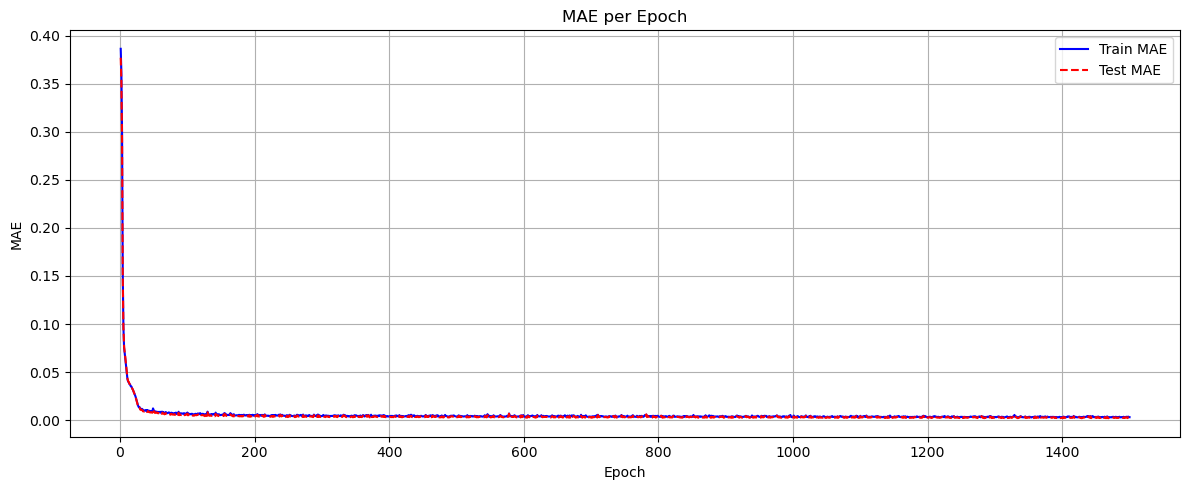

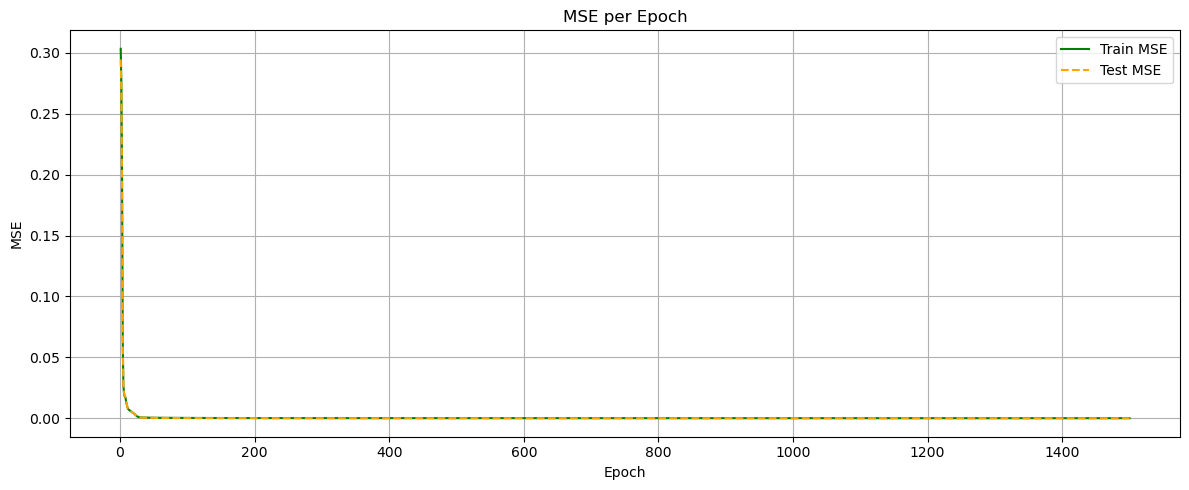

In [13]:
epochs = range(1, N_Epochs + 1)
train_mae_hist = [h[0] for h in train_history]
train_mse_hist = [h[1] for h in train_history]
test_mae_hist = [h[0] for h in test_history]
test_mse_hist = [h[1] for h in test_history]

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mae_hist, label="Train MAE", color="blue")
plt.plot(epochs, test_mae_hist, label="Test MAE", color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MAE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mse_hist, label="Train MSE", color="green")
plt.plot(epochs, test_mse_hist, label="Test MSE", color="orange", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Full test-set prediction vs ground truth

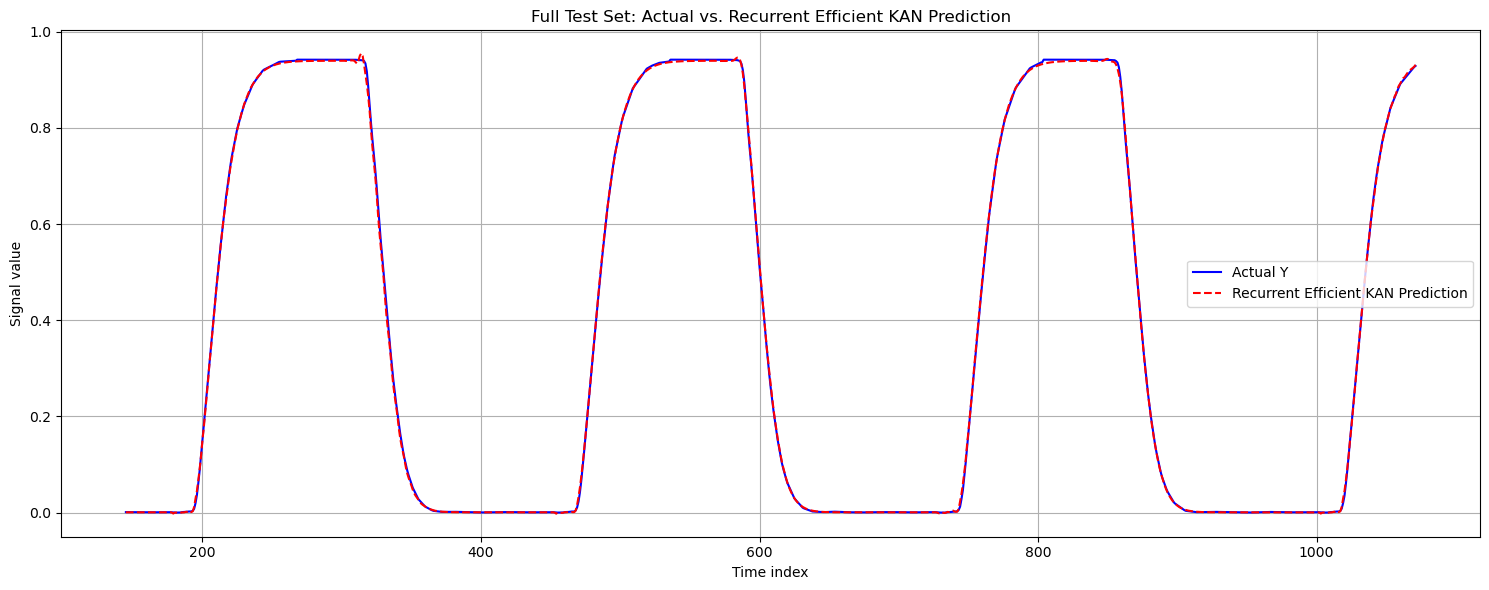

In [14]:
model.eval()
full_predicted_Y_test = np.full_like(Y_test, np.nan, dtype=np.float64)

with torch.no_grad():
    for idx in range(len(test_dataset)):
        x_win, _ = test_dataset[idx]
        x_win = x_win.unsqueeze(0).to(device)
        y_pred_win = model(x_win).cpu().squeeze(0).numpy()

        start_idx = idx + Context_Len
        end_idx = start_idx + Pred_Len
        if start_idx < len(Y_test):
            full_predicted_Y_test[start_idx:min(end_idx, len(Y_test))] = y_pred_win[:min(Pred_Len, len(Y_test) - start_idx)]

start_plot = 145
plt.figure(figsize=(15, 6))
plt.plot(np.arange(start_plot, len(Y_test)), Y_test[start_plot:], label="Actual Y", color="blue")
plt.plot(np.arange(start_plot, len(full_predicted_Y_test)), full_predicted_Y_test[start_plot:],
         label="Recurrent Efficient KAN Prediction", color="red", linestyle="--")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.title("Full Test Set: Actual vs. Recurrent Efficient KAN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()